# Первичное исследование GPS-наблюдений INBO
Полный предоставленный CSV: 1 600 000 строк. Это локальная выборка из исторического набора, а не вся база INBO.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display
from src.config import INPUT, INTERIM, PROCESSED
print(sys.version)
print("Python:", sys.executable)

3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)]
Python: <project>\.venv\Scripts\python.exe


## Проверка исходного файла
Читаем только первые 100 строк. Формат: UTF-8, разделитель запятая, десятичная точка. Большой CSV целиком не печатаем.

In [2]:
preview = pd.read_csv(INPUT, nrows=100)
print(preview.shape)
display(preview.head(5))

(100, 33)


,id,type,language,license,rightsHolder,accessRights,datasetID,institutionCode,datasetName,ownerInstitutionCode,...,decimalLatitude,decimalLongitude,geodeticDatum,coordinateUncertaintyInMeters,georeferenceSources,georeferenceVerificationStatus,scientificName,kingdom,taxonRank,vernacularName
0,801:20130517200539,Event,en,http://creativecommons.org/publicdomain/zero/1.0/,INBO,http://www.inbo.be/en/norms-for-data-use,https://doi.org/10.15468/02omly,INBO,Bird tracking - GPS tracking of Lesser Black-b...,INBO/VLIZ/UGent/UA,...,51.233483,2.930108,WGS84,6,GPS,unverified,Larus argentatus,Animalia,species,Herring Gull
1,801:20130517223523,Event,en,http://creativecommons.org/publicdomain/zero/1.0/,INBO,http://www.inbo.be/en/norms-for-data-use,https://doi.org/10.15468/02omly,INBO,Bird tracking - GPS tracking of Lesser Black-b...,INBO/VLIZ/UGent/UA,...,51.233446,2.930020,WGS84,14,GPS,unverified,Larus argentatus,Animalia,species,Herring Gull
2,801:20130518033642,Event,en,http://creativecommons.org/publicdomain/zero/1.0/,INBO,http://www.inbo.be/en/norms-for-data-use,https://doi.org/10.15468/02omly,INBO,Bird tracking - GPS tracking of Lesser Black-b...,INBO/VLIZ/UGent/UA,...,51.233514,2.930039,WGS84,14,GPS,unverified,Larus argentatus,Animalia,species,Herring Gull
3,801:20130518064136,Event,en,http://creativecommons.org/publicdomain/zero/1.0/,INBO,http://www.inbo.be/en/norms-for-data-use,https://doi.org/10.15468/02omly,INBO,Bird tracking - GPS tracking of Lesser Black-b...,INBO/VLIZ/UGent/UA,...,51.238040,2.922763,WGS84,15,GPS,unverified,Larus argentatus,Animalia,species,Herring Gull
4,801:20130518091123,Event,en,http://creativecommons.org/publicdomain/zero/1.0/,INBO,http://www.inbo.be/en/norms-for-data-use,https://doi.org/10.15468/02omly,INBO,Bird tracking - GPS tracking of Lesser Black-b...,INBO/VLIZ/UGent/UA,...,51.233480,2.930142,WGS84,12,GPS,unverified,Larus argentatus,Animalia,species,Herring Gull


## Полный профиль
Используем сериализованную копию всего CSV. pandas 3 применяет строки Arrow по умолчанию; утверждение о повсеместном object из старых примеров здесь не действует.

In [3]:
df = pd.read_parquet(INTERIM / "source.parquet")
profile = pd.DataFrame({"тип": df.dtypes.astype(str), "уникальных": df.nunique(), "пропусков": df.isna().sum(), "доля пропусков": df.isna().mean(), "доля уникальных": df.nunique()/len(df), "байт памяти": df.memory_usage(deep=True,index=False)})
print("Размер:", df.shape)
display(profile)
df.info(memory_usage="deep")

Размер: (1600000, 33)


,тип,уникальных,пропусков,доля пропусков,доля уникальных,байт памяти
id,str,1600000,0,0.000000,1.000000e+00,42856021
type,str,1,0,0.000000,6.250000e-07,20800000
language,str,1,0,0.000000,6.250000e-07,16000000
license,str,1,0,0.000000,6.250000e-07,91200000
rightsHolder,str,1,0,0.000000,6.250000e-07,19200000
accessRights,str,1,0,0.000000,6.250000e-07,76800000
datasetID,str,1,0,0.000000,6.250000e-07,62400000
institutionCode,str,1,0,0.000000,6.250000e-07,19200000
datasetName,str,1,0,0.000000,6.250000e-07,198400000
ownerInstitutionCode,str,1,0,0.000000,6.250000e-07,41600000


<class 'pandas.DataFrame'>
RangeIndex: 1600000 entries, 0 to 1599999
Data columns (total 33 columns):
 #   Column                               Non-Null Count    Dtype  
---  ------                               --------------    -----  
 0   id                                   1600000 non-null  str    
 1   type                                 1600000 non-null  str    
 2   language                             1600000 non-null  str    
 3   license                              1600000 non-null  str    
 4   rightsHolder                         1600000 non-null  str    
 5   accessRights                         1600000 non-null  str    
 6   datasetID                            1600000 non-null  str    
 7   institutionCode                      1600000 non-null  str    
 8   datasetName                          1600000 non-null  str    
 9   ownerInstitutionCode                 1600000 non-null  str    
 10  basisOfRecord                        1600000 non-null  str    
 11  informati

## Повторы и диапазоны

In [4]:
print("Полных повторов:", df.duplicated().sum())
print("Повторов id:", df.id.duplicated().sum())
display(df.describe().T)
print("Даты:", df.eventDate.min(), df.eventDate.max())

Полных повторов: 0
Повторов id: 0


,count,mean,std,min,25%,50%,75%,max
minimumElevationInMeters,1600000.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
minimumDistanceAboveSurfaceInMeters,1599989.0,29.663592,98.409102,-1100.000000,0.000000,7.000000,24.000000,9691.000000
decimalLatitude,1600000.0,49.921861,4.952521,12.355240,51.079585,51.218155,51.243788,57.491783
decimalLongitude,1600000.0,2.075908,3.210309,-17.487944,2.799701,2.933857,3.041269,17.265446
coordinateUncertaintyInMeters,1600000.0,9.427542,9.329204,1.000000,3.000000,7.000000,13.000000,755.000000


Даты: 2013-05-17T20:05:39Z 2016-07-22T08:38:56Z


## Распределение пропусков
Пол не заполняем модой, высоту не заполняем медианой: это создало бы ложные биологические измерения.

In [5]:
display(df.groupby("scientificName").agg(rows=("id","size"), missing_sex=("sex",lambda s:s.isna().sum()), missing_height=("minimumDistanceAboveSurfaceInMeters",lambda s:s.isna().sum())))

,rows,missing_sex,missing_height
scientificName,,,
Larus argentatus,1034332,0,11
Larus fuscus,565668,190,0


## Наблюдения по годам

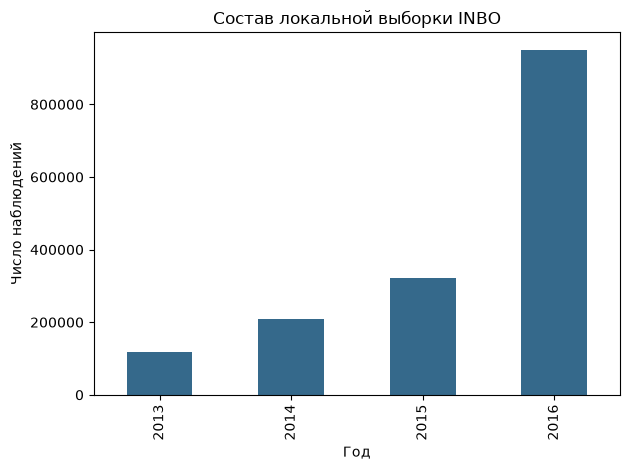

In [6]:
import matplotlib.pyplot as plt
years = pd.to_datetime(df.eventDate, utc=True).dt.year.value_counts().sort_index()
years.plot.bar(color="#35698b")
plt.xlabel("Год")
plt.ylabel("Число наблюдений")
plt.title("Состав локальной выборки INBO")
plt.tight_layout()
plt.show()

## План очистки
Переименовать поля, задать типы и дату UTC; проверить служебные пропуски и повторы; сохранить неизвестный пол и высоту как NA с флагами. Координаты проверить по допустимым границам. Отрицательные высоты отметить отдельно. Сравнить IQR и MAD; подозрительные высоты оставить для предметной проверки. GPS-точки не являются независимыми птицами, поэтому число строк нельзя использовать как оценку численности популяции.